# 1. Import Required Libraries

In [1]:
#import required libraries
import pandas as pd
import numpy as np
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


# 2. Load the Dataset

In [2]:
df = pd.read_csv("dataset-tickets-multi-lang3-4k.csv")
print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (4000, 17)


# 3. Understand the Dataset

In [3]:
print(df.columns.tolist())

['subject', 'body', 'answer', 'type', 'queue', 'priority', 'language', 'business_type', 'tag_1', 'tag_2', 'tag_3', 'tag_4', 'tag_5', 'tag_6', 'tag_7', 'tag_8', 'tag_9']


In [4]:
# Display the first 5 records
df.head()

,subject,body,answer,type,queue,priority,language,business_type,tag_1,tag_2,tag_3,tag_4,tag_5,tag_6,tag_7,tag_8,tag_9
0,Problema crítico del servidor requiere atenció...,Es necesaria una investigación inmediata sobre...,Estamos investigando urgentemente el problema ...,Incident,Technical Support,high,es,IT Services,Urgent Issue,Service Disruption,Incident Report,Service Recovery,System Maintenance,NaN,NaN,NaN,NaN
1,Anfrage zur Verfügbarkeit des Dell XPS 13 9310,"Sehr geehrter Kundenservice,\n\nich hoffe, die...","Sehr geehrter <name>,\n\nvielen Dank, dass Sie...",Request,Customer Service,low,de,Tech Online Store,Sales Inquiry,Product Support,Customer Service,Order Issue,Returns and Exchanges,NaN,NaN,NaN,NaN
2,Erro na Autocompletação de Código do IntelliJ ...,"Prezado Suporte ao Cliente <name>,\n\nEstou es...","Prezado <name>,\n\nObrigado por entrar em cont...",Incident,Technical Support,high,pt,IT Services,Technical Support,Software Bug,Problem Resolution,Urgent Issue,IT Support,NaN,NaN,NaN,NaN
3,Urgent Assistance Required: AWS Service,"Dear IT Services Support Team, \n\nI am reachi...","Dear <name>,\n\nThank you for reaching out reg...",Request,IT Support,high,en,IT Services,IT Support,Urgent Issue,Service Notification,Cloud Services,Problem Resolution,Technical Guidance,Performance Tuning,NaN,NaN
4,Problème d'affichage de MacBook Air,Cher équipe de support du magasin en ligne Tec...,"Cher <name>,\n\nMerci de nous avoir contactés ...",Incident,Product Support,low,fr,Tech Online Store,Technical Support,Product Support,Hardware Failure,Service Recovery,Routine Request,NaN,NaN,NaN,NaN


# 4. Check Target Variables

The queue will be used for ticket routing,
and priority will be used for urgency prediction.

In [5]:
# Check the different support queues
print("Queue categories:")
print(df["queue"].value_counts())

Queue categories:
queue
Technical Support                  1317
Product Support                     690
Customer Service                    627
IT Support                          445
Billing and Payments                338
Returns and Exchanges               197
Service Outages and Maintenance     141
Sales and Pre-Sales                 137
General Inquiry                      55
Human Resources                      53
Name: count, dtype: int64


In [6]:
# Check the different priority levels
print("\nPriority categories:")
print(df["priority"].value_counts())


Priority categories:
priority
high      1649
medium    1603
low        748
Name: count, dtype: int64


# 5. Select English Tickets

The dataset contains tickets in multiple languages.
For the first version of the model, we use only English tickets
to keep the text classification process simple and explainable.

In [7]:
# Create a copy of the original dataset
df_clean = df.copy()

# Replace missing subject/body values with empty text
df_clean["subject"] = df_clean["subject"].fillna("")
df_clean["body"] = df_clean["body"].fillna("")

# Combine subject and body into one text field
df_clean["ticket_text"] = (
    df_clean["subject"] + " " + df_clean["body"]
)

# Keep only English tickets
df_en = df_clean[df_clean["language"] == "en"].copy()

print("English tickets:", len(df_en))

English tickets: 1391


# 6. Clean the Ticket Text

In [8]:
# Function to clean ticket text
def clean_text(text):
    # Convert text to lowercase
    text = text.lower()
    
    # Remove placeholders such as <name> and <acc_num>
    text = re.sub(r"<[^>]+>", " ", text)
    
    # Remove extra spaces
    text = re.sub(r"\s+", " ", text)
    
    # Remove spaces from the beginning and end
    return text.strip()

In [9]:
# Create a new column with cleaned text
df_en["clean_text"] = df_en["ticket_text"].apply(clean_text)

# Display the original and cleaned text
df_en[["ticket_text", "clean_text"]].head(2)

,ticket_text,clean_text
3,Urgent Assistance Required: AWS Service Dear I...,urgent assistance required: aws service dear i...
5,Urgent: Issue with Zoom Screen Sharing Feature...,urgent: issue with zoom screen sharing feature...


In [10]:
# Check whether any cleaned ticket is empty
print(
    "Empty cleaned tickets:",
    (df_en["clean_text"].str.strip() == "").sum()
)

Empty cleaned tickets: 0


# 7. Define Input and Target Variables

The input to the model is the cleaned ticket text.
We have two target variables:
1. Queue - used for support ticket routing
2. Priority - used for urgency prediction

In [11]:
# Input text for the ML models
X = df_en["clean_text"]

# Target for queue prediction
y_queue = df_en["queue"]

# Target for priority prediction
y_priority = df_en["priority"]

# Display basic information
print("Total tickets:", len(X))
print("Number of queue classes:", y_queue.nunique())
print("Number of priority classes:", y_priority.nunique())

Total tickets: 1391
Number of queue classes: 10
Number of priority classes: 3


# 8. Split Data into Training and Testing Sets

Divide the dataset into:
- 80% training data to train the model
- 20% testing data to evaluate the model on unseen tickets.


In [12]:
# Import train_test_split
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing data
X_train, X_test, y_queue_train, y_queue_test, y_priority_train, y_priority_test = train_test_split(
    X,
    y_queue,
    y_priority,
    test_size=0.2,
    random_state=42,
    stratify=y_queue
)

# Display the split sizes
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1112
Testing samples: 279


# 9. Convert Text into TF-IDF Features

Machine learning models cannot directly understand text.
TF-IDF converts the ticket text into numerical features.

By using:
- Single words (unigrams)
- Two-word combinations (bigrams)

In [13]:
# Import TF-IDF vectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

# Learn TF-IDF features from training data
X_train_tfidf = vectorizer.fit_transform(X_train)

# Transform testing data using the same vectorizer
X_test_tfidf = vectorizer.transform(X_test)

# Display the resulting shapes
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (1112, 5000)
Testing TF-IDF shape: (279, 5000)


# 10. Train the Queue Prediction Model

We use Logistic Regression to classify tickets into
one of the 10 support queues.

Class weights are balanced because some queues have
more training examples than others.

In [14]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create the queue classification model
queue_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# Train the model using the TF-IDF features
queue_model.fit(X_train_tfidf, y_queue_train)

print("Queue model training completed!")

Queue model training completed!


# 11. Predict Support Queue

The trained model is now used to predict the queue
for tickets that it has not seen during training.

In [15]:
# Predict the queue for the test tickets
y_queue_pred = queue_model.predict(X_test_tfidf)

# Display the first 10 predictions
print("Predicted queues:")
print(y_queue_pred[:10])

# Display the actual queues
print("\nActual queues:")
print(y_queue_test.iloc[:10].values)

Predicted queues:
['Technical Support' 'Customer Service' 'Technical Support'
 'Technical Support' 'IT Support' 'Product Support' 'Sales and Pre-Sales'
 'Billing and Payments' 'Returns and Exchanges'
 'Service Outages and Maintenance']

Actual queues:
<ArrowStringArray>
[              'Technical Support',                'Customer Service',
               'Technical Support',                      'IT Support',
                'Customer Service',                      'IT Support',
               'Technical Support',            'Billing and Payments',
           'Returns and Exchanges', 'Service Outages and Maintenance']
Length: 10, dtype: str


# 12. Evaluate the Queue Model

We evaluate the model using:

- Accuracy
- Precision
- Recall
- F1-score

F1-score is especially important because our queue classes
are not equally distributed.

In [16]:
# Import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report

# Calculate accuracy
queue_accuracy = accuracy_score(y_queue_test, y_queue_pred)

print("Queue Model Accuracy:", queue_accuracy)

# Display precision, recall and F1-score
print("\nQueue Model Classification Report:")
print(
    classification_report(
        y_queue_test,
        y_queue_pred,
        zero_division=0
    )
)

Queue Model Accuracy: 0.4731182795698925

Queue Model Classification Report:
                                 precision    recall  f1-score   support

           Billing and Payments       0.74      0.83      0.78        24
               Customer Service       0.41      0.35      0.38        43
                General Inquiry       0.00      0.00      0.00         3
                Human Resources       0.00      0.00      0.00         3
                     IT Support       0.27      0.35      0.31        34
                Product Support       0.34      0.45      0.39        47
          Returns and Exchanges       0.47      0.69      0.56        13
            Sales and Pre-Sales       0.35      0.75      0.48         8
Service Outages and Maintenance       0.82      0.90      0.86        10
              Technical Support       0.66      0.43      0.52        94

                       accuracy                           0.47       279
                      macro avg       0.41   

# 13. Queue Prediction Confusion Matrix

The confusion matrix shows which queues are being
correctly classified and which queues are being confused.

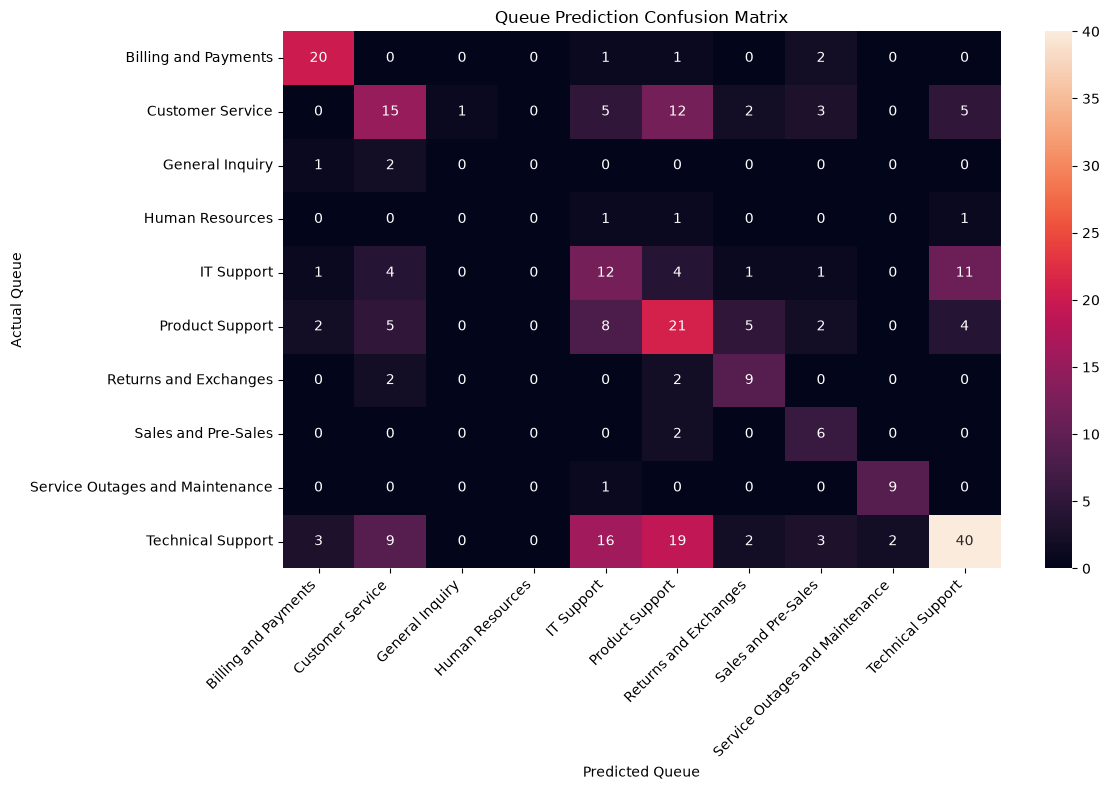

In [17]:
# Import confusion matrix
from sklearn.metrics import confusion_matrix

# Create the confusion matrix
cm = confusion_matrix(
    y_queue_test,
    y_queue_pred,
    labels=queue_model.classes_
)

# Plot the confusion matrix
plt.figure(figsize=(12, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=queue_model.classes_,
    yticklabels=queue_model.classes_
)

plt.xlabel("Predicted Queue")
plt.ylabel("Actual Queue")
plt.title("Queue Prediction Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Confusion Matrix Observation

The confusion matrix shows that the model performs well for
Billing and Payments and Service Outages and Maintenance.

However, Technical Support, IT Support, and Product Support
are frequently confused with each other because their ticket
descriptions can contain similar technical terms.

General Inquiry and Human Resources have very few test samples,
which limits the model's ability to learn these categories effectively.

# 14. Train the Priority Prediction Model

The priority model predicts the urgency level of a support ticket.

The three possible classes are:
- Low
- Medium
- High

We use Logistic Regression because it works well for
multiclass text classification.

In [18]:
# Create the priority classification model
priority_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# Train the model using the training TF-IDF features
priority_model.fit(X_train_tfidf, y_priority_train)

print("Priority model training completed!")

Priority model training completed!


# 15. Predict Ticket Priority

The trained model is used to predict the priority
of unseen test tickets.

In [19]:
# Predict priority for the test tickets
y_priority_pred = priority_model.predict(X_test_tfidf)

# Display the first 10 predictions
print("Predicted priorities:")
print(y_priority_pred[:10])

# Display the actual priorities
print("\nActual priorities:")
print(y_priority_test.iloc[:10].values)

Predicted priorities:
['high' 'medium' 'high' 'high' 'high' 'low' 'low' 'medium' 'medium' 'high']

Actual priorities:
<ArrowStringArray>
['high', 'medium', 'low', 'high', 'high', 'low', 'high', 'low', 'medium',
 'high']
Length: 10, dtype: str


# 16. Evaluate the Priority Model

We evaluate the priority model using accuracy,
precision, recall, and F1-score.

In [20]:
# Calculate priority model accuracy
priority_accuracy = accuracy_score(
    y_priority_test,
    y_priority_pred
)

print("Priority Model Accuracy:", priority_accuracy)

# Display the classification report
print("\nPriority Model Classification Report:")

print(
    classification_report(
        y_priority_test,
        y_priority_pred,
        zero_division=0
    )
)

Priority Model Accuracy: 0.5949820788530465

Priority Model Classification Report:
              precision    recall  f1-score   support

        high       0.71      0.64      0.67       118
         low       0.39      0.47      0.42        47
      medium       0.59      0.61      0.60       114

    accuracy                           0.59       279
   macro avg       0.56      0.57      0.56       279
weighted avg       0.61      0.59      0.60       279



# 17. Priority Prediction Confusion Matrix

The confusion matrix shows how well the model distinguishes
between Low, Medium, and High priority tickets.

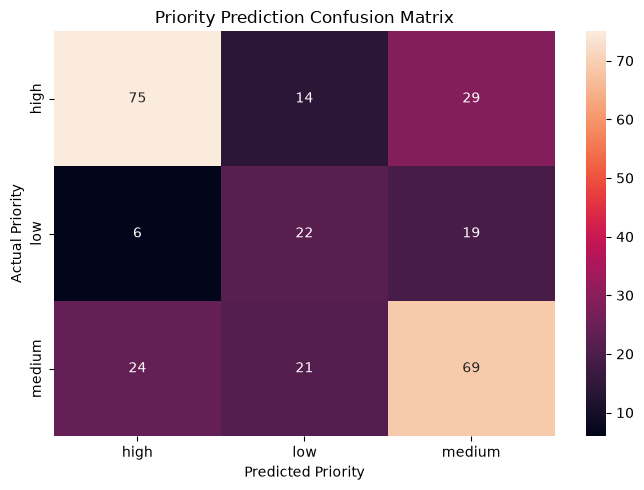

In [21]:
# Create the priority confusion matrix
priority_cm = confusion_matrix(
    y_priority_test,
    y_priority_pred,
    labels=priority_model.classes_
)

# Plot the confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    priority_cm,
    annot=True,
    fmt="d",
    xticklabels=priority_model.classes_,
    yticklabels=priority_model.classes_
)

plt.xlabel("Predicted Priority")
plt.ylabel("Actual Priority")
plt.title("Priority Prediction Confusion Matrix")
plt.tight_layout()
plt.show()

### Confusion Matrix Observation

The confusion matrix shows that the model correctly identifies
most High and Medium priority tickets.

Some Low priority tickets are classified as Medium or High,
which indicates that the model has difficulty distinguishing
lower urgency from more urgent tickets.

The diagonal values represent correct predictions, while the
off-diagonal values represent incorrect predictions.

# 18. Confidence Score for Queue Prediction

The model can provide probabilities for each possible queue.
We use the highest probability as the confidence score.
Low-confidence predictions can be sent for human review.

In [22]:
# Get probability for each queue
queue_probabilities = queue_model.predict_proba(X_test_tfidf)

# Get the highest probability for each ticket
queue_confidence = queue_probabilities.max(axis=1)

# Display the first 10 confidence scores
print("First 10 queue confidence scores:")
print(queue_confidence[:10])

First 10 queue confidence scores:
[0.36436642 0.22809552 0.37194041 0.35453425 0.19152578 0.18531279
 0.18046869 0.60284001 0.64970139 0.40670794]


# 19. Flag Low-Confidence Predictions

Predictions with confidence below 50% are flagged for human review.

This prevents the system from automatically routing tickets
when the model is not sufficiently confident.

In [23]:
# Set the confidence threshold
confidence_threshold = 0.50

# Flag predictions below the threshold
human_review = queue_confidence < confidence_threshold

# Count tickets that need human review
print("Tickets needing human review:", human_review.sum())

# Show the percentage
review_percentage = human_review.mean() * 100

print("Percentage needing human review:", round(review_percentage, 2), "%")

Tickets needing human review: 260
Percentage needing human review: 93.19 %


# 20. Analyze Queue Prediction Confidence

We examine the confidence scores to understand how confident
the queue model is about its predictions.

This helps us choose a suitable threshold for human review.

count    279.000000
mean       0.288189
std        0.120782
min        0.150450
25%        0.218292
50%        0.255523
75%        0.312568
max        0.855680
dtype: float64


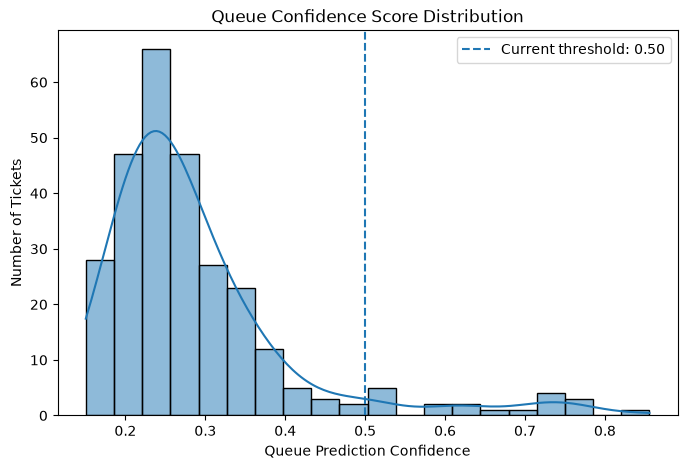

In [24]:
# Display summary statistics for confidence scores
print(pd.Series(queue_confidence).describe())

# Plot the confidence score distribution
plt.figure(figsize=(8, 5))
sns.histplot(queue_confidence, bins=20, kde=True)

plt.axvline(
    0.50,
    linestyle="--",
    label="Current threshold: 0.50"
)

plt.xlabel("Queue Prediction Confidence")
plt.ylabel("Number of Tickets")
plt.title("Queue Confidence Score Distribution")
plt.legend()
plt.show()

# 22. Improve TF-IDF Features

The baseline model achieved 47.31% queue prediction accuracy.

In this step, we improve text feature extraction by:
- Increasing the maximum vocabulary size to 10,000.
- Ignoring words that appear in only one training ticket.
- Applying sublinear term frequency.

Keep the same training and testing split for a fair comparison.

In [25]:
# Create an improved TF-IDF vectorizer
improved_vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# Learn features from training tickets
X_train_tfidf_2 = improved_vectorizer.fit_transform(X_train)

# Transform test tickets using the same vocabulary
X_test_tfidf_2 = improved_vectorizer.transform(X_test)

# Display the feature dimensions
print("Improved training shape:", X_train_tfidf_2.shape)
print("Improved testing shape:", X_test_tfidf_2.shape)

Improved training shape: (1112, 10000)
Improved testing shape: (279, 10000)


# 23. Train the Improved Queue Model

We train a second Logistic Regression model using the improved
TF-IDF features.

We will compare this model with the baseline model to check
whether the changes improve queue classification.

In [26]:
# Create the improved queue model
improved_queue_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# Train using the improved TF-IDF features
improved_queue_model.fit(X_train_tfidf_2, y_queue_train)

print("Improved queue model training completed!")

Improved queue model training completed!


# 24. Evaluate the Improved Queue Model

We evaluate the improved model using accuracy and F1-score.

The results will be compared with the baseline model.

In [27]:
# Predict queues for the test tickets
y_queue_pred_2 = improved_queue_model.predict(X_test_tfidf_2)

# Calculate improved accuracy
improved_accuracy = accuracy_score(y_queue_test, y_queue_pred_2)

# Generate the classification report
print("Improved Queue Accuracy:", round(improved_accuracy, 4))

print("\nImproved Classification Report:")
print(classification_report(
    y_queue_test,
    y_queue_pred_2,
    zero_division=0
))

Improved Queue Accuracy: 0.4839

Improved Classification Report:
                                 precision    recall  f1-score   support

           Billing and Payments       0.70      0.79      0.75        24
               Customer Service       0.44      0.37      0.41        43
                General Inquiry       0.00      0.00      0.00         3
                Human Resources       0.00      0.00      0.00         3
                     IT Support       0.28      0.35      0.31        34
                Product Support       0.34      0.45      0.39        47
          Returns and Exchanges       0.42      0.62      0.50        13
            Sales and Pre-Sales       0.46      0.75      0.57         8
Service Outages and Maintenance       0.82      0.90      0.86        10
              Technical Support       0.65      0.47      0.54        94

                       accuracy                           0.48       279
                      macro avg       0.41      0.47     

In [28]:
# ## Comparison of Queue Models

# The baseline Logistic Regression model achieved 47.31% accuracy
# # and a macro F1-score of 0.43.

# The improved TF-IDF model achieved 48.39% accuracy and a macro
# F1-score of 0.43.

# The improved model showed a small increase in accuracy, but the
# macro F1-score remained unchanged. Further improvements may be
# needed to distinguish between similar support categories and
# # to improve predictions for underrepresented classes.

# 25. Compare Baseline and Improved Models

We compare the accuracy, macro F1-score, and weighted F1-score
of both queue models using a bar chart.

,Metric,Baseline,Improved
0,Accuracy,0.473,0.484
1,Macro F1,0.427,0.432
2,Weighted F1,0.472,0.483


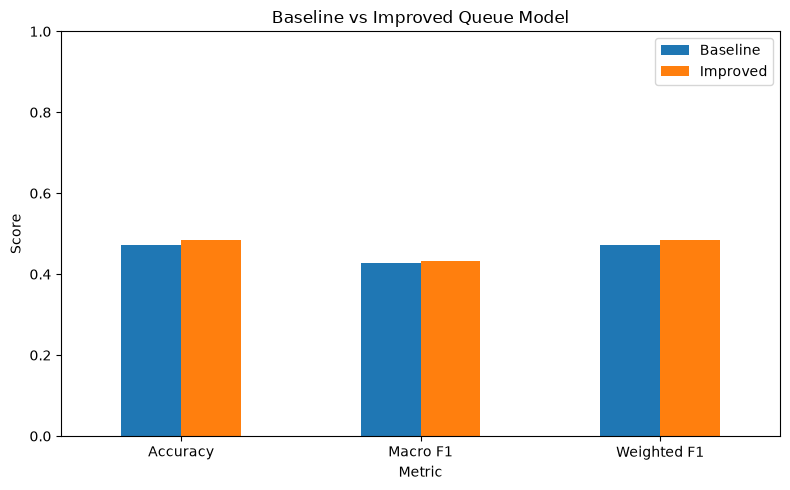

In [29]:
# Calculate F1-scores for both models
from sklearn.metrics import f1_score

baseline_macro_f1 = f1_score(
    y_queue_test, y_queue_pred, average="macro", zero_division=0
)

baseline_weighted_f1 = f1_score(
    y_queue_test, y_queue_pred, average="weighted", zero_division=0
)

improved_macro_f1 = f1_score(
    y_queue_test, y_queue_pred_2, average="macro", zero_division=0
)

improved_weighted_f1 = f1_score(
    y_queue_test, y_queue_pred_2, average="weighted", zero_division=0
)

# Store the results for comparison
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Macro F1", "Weighted F1"],
    "Baseline": [
        queue_accuracy, baseline_macro_f1, baseline_weighted_f1
    ],
    "Improved": [
        improved_accuracy, improved_macro_f1, improved_weighted_f1
    ]
})

# Display the comparison table
display(comparison.round(3))

# Plot the comparison
comparison.set_index("Metric").plot(kind="bar", figsize=(8, 5))

plt.title("Baseline vs Improved Queue Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 27. Generate Final Queue Predictions and Confidence

Use the selected model to predict support queues and
calculate the highest predicted probability for each test ticket.

Tickets with low confidence will be flagged for human review.

In [30]:
# Predict queues using the improved model
final_queue_predictions = improved_queue_model.predict(X_test_tfidf_2)

# Get probabilities for each queue
final_queue_probabilities = improved_queue_model.predict_proba(X_test_tfidf_2)

# Get the highest probability for each prediction
final_queue_confidence = final_queue_probabilities.max(axis=1)

# Display the first 10 results
print("Predicted queues:", final_queue_predictions[:10])
print("Confidence scores:", final_queue_confidence[:10])

Predicted queues: ['Technical Support' 'Customer Service' 'Technical Support'
 'Technical Support' 'IT Support' 'Product Support' 'Sales and Pre-Sales'
 'Billing and Payments' 'Returns and Exchanges'
 'Service Outages and Maintenance']
Confidence scores: [0.31800374 0.21913122 0.31819358 0.34115003 0.1885992  0.18196791
 0.16514627 0.50340894 0.58776922 0.30666452]


# 28. Flag Low-Confidence Tickets

We use a confidence threshold of 0.50.

Tickets with confidence below 0.50 are flagged for human review.
This helps prevent uncertain predictions from being routed
automatically without checking.

In [31]:
# Set the confidence threshold
confidence_threshold = 0.50

# Identify tickets that need human review
final_human_review = final_queue_confidence < confidence_threshold

# Count tickets requiring review
review_count = final_human_review.sum()

# Calculate the review percentage
review_percentage = final_human_review.mean() * 100

print("Tickets needing human review:", review_count)
print("Percentage needing human review:", round(review_percentage, 2), "%")

Tickets needing human review: 265
Percentage needing human review: 94.98 %


# 29. Final Queue Prediction Results

Combine the model predictions and confidence scores
into a table to inspect the ticket routing results.

In [32]:
# Create a results table
queue_results = pd.DataFrame({
    "Ticket": X_test.values,
    "Actual Queue": y_queue_test.values,
    "Predicted Queue": final_queue_predictions,
    "Confidence": final_queue_confidence.round(3),
    "Human Review": final_human_review
})

# Display the first 10 results
display(queue_results.head(10))

,Ticket,Actual Queue,Predicted Queue,Confidence,Human Review
0,urgent: networking issues with cisco router is...,Technical Support,Technical Support,0.318,True
1,"dear customer support, i am writing to notify ...",Customer Service,Customer Service,0.219,True
2,frequent issues with cisco router isr4331 dear...,Technical Support,Technical Support,0.318,True
3,critical router disconnections dear customer s...,IT Support,Technical Support,0.341,True
4,urgent assistance required for it optimization...,Customer Service,IT Support,0.189,True
5,querying error assistance dear customer suppor...,IT Support,Product Support,0.182,True
6,request for extension integration dear custome...,Technical Support,Sales and Pre-Sales,0.165,True
7,"billing issue inquiry dear customer support, i...",Billing and Payments,Billing and Payments,0.503,False
8,return request: ink tank leakage issue dear cu...,Returns and Exchanges,Returns and Exchanges,0.588,False
9,critical outage affecting aws dear customer su...,Service Outages and Maintenance,Service Outages and Maintenance,0.307,True


# 30. Combined AI Ticket Triage Results

This section combines the predicted support queue and priority
for each ticket.

Tickets with low queue confidence are flagged for human review.
The table represents the final output of the two ML models.

In [33]:
# Create the combined triage results table
triage_results = pd.DataFrame({
    "Ticket": X_test.values,
    "Actual Queue": y_queue_test.values,
    "Predicted Queue": final_queue_predictions,
    "Queue Confidence": final_queue_confidence.round(3),
    "Actual Priority": y_priority_test.values,
    "Predicted Priority": y_priority_pred,
    "Human Review": final_human_review
})

# Display the first 10 triage results
display(triage_results.head(10))

,Ticket,Actual Queue,Predicted Queue,Queue Confidence,Actual Priority,Predicted Priority,Human Review
0,urgent: networking issues with cisco router is...,Technical Support,Technical Support,0.318,high,high,True
1,"dear customer support, i am writing to notify ...",Customer Service,Customer Service,0.219,medium,medium,True
2,frequent issues with cisco router isr4331 dear...,Technical Support,Technical Support,0.318,low,high,True
3,critical router disconnections dear customer s...,IT Support,Technical Support,0.341,high,high,True
4,urgent assistance required for it optimization...,Customer Service,IT Support,0.189,high,high,True
5,querying error assistance dear customer suppor...,IT Support,Product Support,0.182,low,low,True
6,request for extension integration dear custome...,Technical Support,Sales and Pre-Sales,0.165,high,low,True
7,"billing issue inquiry dear customer support, i...",Billing and Payments,Billing and Payments,0.503,low,medium,False
8,return request: ink tank leakage issue dear cu...,Returns and Exchanges,Returns and Exchanges,0.588,medium,medium,False
9,critical outage affecting aws dear customer su...,Service Outages and Maintenance,Service Outages and Maintenance,0.307,high,high,True


# 31. Save the Trained Models

Save the selected queue model, priority model, and TF-IDF
vectorizers using joblib.

These saved files can be loaded later by the Streamlit
application to predict the queue and priority of new tickets.

In [34]:
# Import joblib for saving machine learning models
import joblib
from pathlib import Path

# Create a folder for the trained models
Path("models").mkdir(exist_ok=True)

# Save the improved queue model
joblib.dump(improved_queue_model, "models/queue_model.pkl")

# Save the queue TF-IDF vectorizer
joblib.dump(improved_vectorizer, "models/queue_vectorizer.pkl")

# Save the priority model
joblib.dump(priority_model, "models/priority_model.pkl")

# Save the priority TF-IDF vectorizer
joblib.dump(vectorizer, "models/priority_vectorizer.pkl")

print("All models and vectorizers saved successfully!")

All models and vectorizers saved successfully!


# 32. Load and Test the Saved Models

Load the saved models and vectorizers from the models folder.

This verifies that they can be reused without retraining.

In [35]:
# Load the saved queue model and vectorizer
loaded_queue_model = joblib.load("models/queue_model.pkl")
loaded_queue_vectorizer = joblib.load("models/queue_vectorizer.pkl")

# Load the saved priority model and vectorizer
loaded_priority_model = joblib.load("models/priority_model.pkl")
loaded_priority_vectorizer = joblib.load("models/priority_vectorizer.pkl")

print("All saved models loaded successfully!")

All saved models loaded successfully!


In [36]:
# Select one ticket from the test dataset
sample_ticket = X_test.iloc[0]

# Convert the ticket text into TF-IDF features
queue_features = loaded_queue_vectorizer.transform([sample_ticket])
priority_features = loaded_priority_vectorizer.transform([sample_ticket])

# Predict the support queue and priority
predicted_queue = loaded_queue_model.predict(queue_features)[0]
predicted_priority = loaded_priority_model.predict(priority_features)[0]

print("Ticket:", sample_ticket[:200], "...")
print("Predicted Queue:", predicted_queue)
print("Predicted Priority:", predicted_priority)

Ticket: urgent: networking issues with cisco router isr4331 dear it support team, i am writing to bring to your immediate attention some persistent networking issues we are experiencing with our cisco router  ...
Predicted Queue: Technical Support
Predicted Priority: high


# 33. Build the Streamlit Dashboard

Streamlit provides a simple web interface for our AI ticket
triage system.

Users can enter a support ticket and receive:
- Predicted support queue
- Predicted priority
- Queue confidence score
- Human-review recommendation

In [37]:
!python -m streamlit run app.py

^C


In [38]:
import pandas as pd

# Check how many tickets belong to each queue
print("Tickets in each support queue:")
print(y_queue.value_counts())

# Check the percentage for each queue
print("\nQueue distribution (%):")
print((y_queue.value_counts(normalize=True) * 100).round(2))

Tickets in each support queue:
queue
Technical Support                  468
Product Support                    235
Customer Service                   213
IT Support                         167
Billing and Payments               120
Returns and Exchanges               65
Service Outages and Maintenance     51
Sales and Pre-Sales                 42
General Inquiry                     15
Human Resources                     15
Name: count, dtype: int64

Queue distribution (%):
queue
Technical Support                  33.64
Product Support                    16.89
Customer Service                   15.31
IT Support                         12.01
Billing and Payments                8.63
Returns and Exchanges               4.67
Service Outages and Maintenance     3.67
Sales and Pre-Sales                 3.02
General Inquiry                     1.08
Human Resources                     1.08
Name: proportion, dtype: float64


In [39]:
import joblib

queue_vectorizer = joblib.load("models/queue_vectorizer.pkl")
queue_model = joblib.load("models/queue_model.pkl")

print("Queue model and vectorizer loaded successfully!")

Queue model and vectorizer loaded successfully!


In [40]:
%whos

Variable                     Type                  Data/Info
------------------------------------------------------------
LogisticRegression           type                  <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
Path                         type                  <class 'pathlib.Path'>
TfidfVectorizer              type                  <class 'sklearn.feature_e<...>on.text.TfidfVectorizer'>
X                            Series                3       urgent assistance<...> Length: 1391, dtype: str
X_test                       Series                3056    urgent: networkin<...>, Length: 279, dtype: str
X_test_tfidf                 csr_matrix            <Compressed Sparse Row sp<...>4985)	0.04996436772882454
X_test_tfidf_2               csr_matrix            <Compressed Sparse Row sp<...>9978)	0.05003399341328669
X_train                      Series                22      dear customer car<...> Length: 1112, dtype: str
X_train_tfidf                csr_matrix            <Com

In [41]:
from sklearn.metrics import accuracy_score, classification_report

# Use the improved queue model
y_pred = improved_queue_model.predict(X_test_tfidf_2)

# Check accuracy
print("Improved Queue Model Accuracy:")
print(f"{accuracy_score(y_queue_test, y_pred) * 100:.2f}%")

# Check performance for each support queue
print("\nClassification Report:")
print(classification_report(
    y_queue_test,
    y_pred,
    zero_division=0
))

Improved Queue Model Accuracy:
48.39%

Classification Report:
                                 precision    recall  f1-score   support

           Billing and Payments       0.70      0.79      0.75        24
               Customer Service       0.44      0.37      0.41        43
                General Inquiry       0.00      0.00      0.00         3
                Human Resources       0.00      0.00      0.00         3
                     IT Support       0.28      0.35      0.31        34
                Product Support       0.34      0.45      0.39        47
          Returns and Exchanges       0.42      0.62      0.50        13
            Sales and Pre-Sales       0.46      0.75      0.57         8
Service Outages and Maintenance       0.82      0.90      0.86        10
              Technical Support       0.65      0.47      0.54        94

                       accuracy                           0.48       279
                      macro avg       0.41      0.47      0.

In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Train a new model with balanced class weights
balanced_queue_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

balanced_queue_model.fit(X_train_tfidf_2, y_queue_train)

# Evaluate on the same test data
balanced_predictions = balanced_queue_model.predict(X_test_tfidf_2)

print("Balanced Model Accuracy:")
print(f"{accuracy_score(y_queue_test, balanced_predictions) * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_queue_test,
    balanced_predictions,
    zero_division=0
))

Balanced Model Accuracy:
48.39%

Classification Report:
                                 precision    recall  f1-score   support

           Billing and Payments       0.70      0.79      0.75        24
               Customer Service       0.44      0.37      0.41        43
                General Inquiry       0.00      0.00      0.00         3
                Human Resources       0.00      0.00      0.00         3
                     IT Support       0.28      0.35      0.31        34
                Product Support       0.34      0.45      0.39        47
          Returns and Exchanges       0.42      0.62      0.50        13
            Sales and Pre-Sales       0.46      0.75      0.57         8
Service Outages and Maintenance       0.82      0.90      0.86        10
              Technical Support       0.65      0.47      0.54        94

                       accuracy                           0.48       279
                      macro avg       0.41      0.47      0.43    

In [43]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report
#importing linear svc

In [44]:
# Create the LinearSVC model
svm_model = LinearSVC(
    class_weight="balanced",
    random_state=42,
    max_iter=3000
)

# Train the model
svm_model.fit(X_train_tfidf_2, y_queue_train)

print("LinearSVC model trained successfully!")

LinearSVC model trained successfully!


In [45]:
# Predict support queues
svm_pred = svm_model.predict(X_test_tfidf_2)

# Calculate accuracy
svm_accuracy = accuracy_score(y_queue_test, svm_pred)

print("LinearSVC Model Accuracy:")
print(f"{svm_accuracy * 100:.2f}%")

# Display detailed performance
print("\nClassification Report:")
print(classification_report(
    y_queue_test,
    svm_pred,
    zero_division=0
))

LinearSVC Model Accuracy:
48.75%

Classification Report:
                                 precision    recall  f1-score   support

           Billing and Payments       0.76      0.92      0.83        24
               Customer Service       0.36      0.37      0.37        43
                General Inquiry       0.00      0.00      0.00         3
                Human Resources       0.00      0.00      0.00         3
                     IT Support       0.32      0.32      0.32        34
                Product Support       0.33      0.38      0.36        47
          Returns and Exchanges       0.58      0.54      0.56        13
            Sales and Pre-Sales       0.43      0.38      0.40         8
Service Outages and Maintenance       0.86      0.60      0.71        10
              Technical Support       0.58      0.56      0.57        94

                       accuracy                           0.49       279
                      macro avg       0.42      0.41      0.41   

compare the models

In [46]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Balanced Logistic Regression",
        "LinearSVC"
    ],
    "Accuracy (%)": [
        accuracy_score(y_queue_test, improved_queue_model.predict(X_test_tfidf_2)) * 100,
        accuracy_score(y_queue_test, balanced_predictions) * 100,
        accuracy_score(y_queue_test, svm_pred) * 100
    ],
    "Macro F1": [
        f1_score(y_queue_test, improved_queue_model.predict(X_test_tfidf_2), average="macro", zero_division=0),
        f1_score(y_queue_test, balanced_predictions, average="macro", zero_division=0),
        f1_score(y_queue_test, svm_pred, average="macro", zero_division=0)
    ],
    "Weighted F1": [
        f1_score(y_queue_test, improved_queue_model.predict(X_test_tfidf_2), average="weighted", zero_division=0),
        f1_score(y_queue_test, balanced_predictions, average="weighted", zero_division=0),
        f1_score(y_queue_test, svm_pred, average="weighted", zero_division=0)
    ]
})

print(comparison.round(3))

                          Model  Accuracy (%)  Macro F1  Weighted F1
0           Logistic Regression        48.387     0.432        0.483
1  Balanced Logistic Regression        48.387     0.432        0.483
2                     LinearSVC        48.746     0.412        0.483


Check LinearSVC confidence

In [47]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.svm import LinearSVC
import numpy as np

# Create a LinearSVC model with probability calibration
calibrated_svm = CalibratedClassifierCV(
    estimator=LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=3000
    ),
    method="sigmoid",
    cv=3
)

# Train using the training data only
calibrated_svm.fit(X_train_tfidf_2, y_queue_train)

# Calculate queue probabilities on test data
svm_probabilities = calibrated_svm.predict_proba(X_test_tfidf_2)

# Calculate confidence as the highest estimated probability
svm_confidence = svm_probabilities.max(axis=1)

print("Average estimated queue confidence:",
      round(svm_confidence.mean() * 100, 2), "%")

print("Tickets below 50% confidence:",
      np.sum(svm_confidence < 0.50))

print("Tickets at or above 85% confidence:",
      np.sum(svm_confidence >= 0.50))

print("Total test tickets:", len(svm_confidence))

Average estimated queue confidence: 46.53 %
Tickets below 50% confidence: 172
Tickets at or above 85% confidence: 107
Total test tickets: 279


In [48]:
# Markdown: Check the distribution of queue confidence scores

import numpy as np
import pandas as pd

# Find the lowest confidence score
print("Minimum confidence:",
      round(svm_confidence.min() * 100, 2), "%")

# Find the middle confidence score
print("Median confidence:",
      round(np.median(svm_confidence) * 100, 2), "%")

# Find the highest confidence score
print("Maximum confidence:",
      round(svm_confidence.max() * 100, 2), "%")

# Display summary statistics for all confidence scores
print("\nConfidence distribution:")
print(pd.Series(svm_confidence * 100).describe().round(2))

Minimum confidence: 20.82 %
Median confidence: 43.33 %
Maximum confidence: 75.59 %

Confidence distribution:
count    279.00
mean      46.53
std       13.73
min       20.82
25%       34.45
50%       43.33
75%       57.99
max       75.59
dtype: float64


In [49]:
# Markdown: Compare actual and predicted support queues

import pandas as pd
import numpy as np

# Predict the support queue for each test ticket
calibrated_predictions = calibrated_svm.predict(X_test_tfidf_2)

# Create a results table with actual labels, predictions, and confidence
confidence_results = pd.DataFrame({
    "Actual Queue": y_queue_test.to_numpy(),
    "Predicted Queue": calibrated_predictions,
    "Confidence (%)": svm_confidence * 100
})

# Check whether each prediction matches the actual queue
confidence_results["Correct"] = (
    confidence_results["Actual Queue"]
    == confidence_results["Predicted Queue"]
)

# Display the first 10 test results
print("Sample confidence results:")
print(confidence_results.head(10).round(2).to_string(index=False))

# Calculate the percentage of correctly classified tickets
accuracy = confidence_results["Correct"].mean() * 100

print("\nOverall accuracy (%):")
print(round(accuracy, 2))

Sample confidence results:
                   Actual Queue       Predicted Queue  Confidence (%)  Correct
              Technical Support     Technical Support           69.57     True
               Customer Service      Customer Service           39.69     True
              Technical Support     Technical Support           65.88     True
                     IT Support     Technical Support           74.00    False
               Customer Service     Technical Support           31.04    False
                     IT Support     Technical Support           34.00    False
              Technical Support     Technical Support           28.76     True
           Billing and Payments  Billing and Payments           68.90     True
          Returns and Exchanges Returns and Exchanges           67.65     True
Service Outages and Maintenance     Technical Support           49.23    False

Overall accuracy (%):
50.9


# Analyze prediction accuracy across confidence ranges

In [50]:


# Group tickets according to their confidence scores
confidence_results["Confidence Range"] = pd.cut(
    confidence_results["Confidence (%)"],
    bins=[0, 30, 40, 50, 60, 70, 100],
    labels=[
        "0–30%", "30–40%", "40–50%",
        "50–60%", "60–70%", "70–100%"
    ],
    include_lowest=True
)

# Calculate ticket count, actual accuracy, and average confidence
calibration_summary = confidence_results.groupby(
    "Confidence Range",
    observed=False
).agg(
    Ticket_Count=("Correct", "size"),
    Actual_Accuracy=("Correct", "mean"),
    Average_Confidence=("Confidence (%)", "mean")
)

# Convert actual accuracy to a percentage
calibration_summary["Actual_Accuracy"] *= 100

# Display the summary table
print("Confidence vs Actual Accuracy:")
print(calibration_summary.round(2))

Confidence vs Actual Accuracy:
                  Ticket_Count  Actual_Accuracy  Average_Confidence
Confidence Range                                                   
0–30%                       24            20.83               27.89
30–40%                      90            36.67               34.80
40–50%                      58            46.55               44.23
50–60%                      50            68.00               55.78
60–70%                      41            73.17               64.67
70–100%                     16            81.25               73.34


In [51]:
# Markdown: Count tickets meeting the 50% confidence threshold
#Set the confidence threshold to 50%
threshold = 50.0

# Count tickets with confidence at or above 50%
high_confidence_count = (
    confidence_results["Confidence (%)"] >= threshold
).sum()

# Count all test tickets
total_tickets = len(confidence_results)

# Display the results
print("Confidence threshold:", threshold, "%")
print("Tickets meeting threshold:", high_confidence_count)
print("Tickets requiring review:",
      total_tickets - high_confidence_count)

Confidence threshold: 50.0 %
Tickets meeting threshold: 107
Tickets requiring review: 172


# Visualize Queue Confidence Distribution

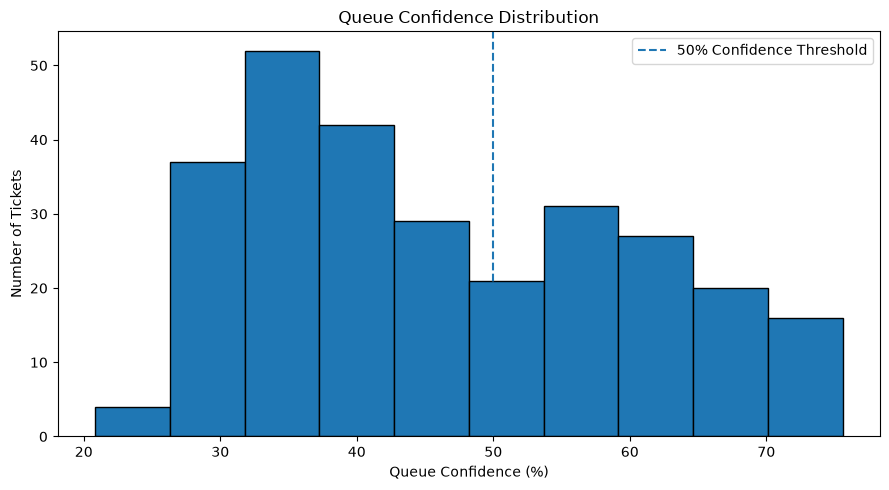

In [52]:

import matplotlib.pyplot as plt

# Create a histogram of queue confidence scores
plt.figure(figsize=(9, 5))

plt.hist(
    confidence_results["Confidence (%)"],
    bins=10,
    edgecolor="black"
)

# Mark the 50% confidence threshold
plt.axvline(
    x=50,
    linestyle="--",
    label="50% Confidence Threshold"
)

# Add chart title and labels
plt.title("Queue Confidence Distribution")
plt.xlabel("Queue Confidence (%)")
plt.ylabel("Number of Tickets")

# Display the legend and chart
plt.legend()
plt.tight_layout()
plt.show()

In [56]:
# Markdown: Launch the Streamlit Dashboard

# Start the ticket triage application
!python -m streamlit run app.py

^C


## Streamlit Dashboard Testing Results

- Successfully launched the Streamlit application.
- Tested account access, Wi-Fi, and payment issues.
- Verified predicted support queues and priorities.
- Verified queue confidence percentages.
- Confirmed tickets below 50% are flagged for manual review.
- Confirmed recent predictions appear in the history table.
- All three sample tickets were flagged for manual review.

In [57]:
# Markdown: Save the calibrated queue model

import joblib
from pathlib import Path

# Create the models folder if it does not exist
models_dir = Path("models")
models_dir.mkdir(exist_ok=True)

# Save the calibrated model
joblib.dump(
    calibrated_svm,
    models_dir / "calibrated_queue_model.pkl"
)

print("Calibrated queue model saved successfully!")

Calibrated queue model saved successfully!


In [58]:
# Markdown: Save the matching queue vectorizer

joblib.dump(
    improved_vectorizer,
    models_dir / "calibrated_queue_vectorizer.pkl"
)

print("Queue vectorizer saved successfully!")

Queue vectorizer saved successfully!


In [59]:
# Markdown: Verify saved model files

print("Model file exists:",
      (models_dir / "calibrated_queue_model.pkl").exists())

print("Vectorizer file exists:",
      (models_dir / "calibrated_queue_vectorizer.pkl").exists())

Model file exists: True
Vectorizer file exists: True


In [60]:
# Markdown: Load the saved calibrated model and vectorizer

import joblib

# Load the calibrated queue model
saved_model = joblib.load(
    "models/calibrated_queue_model.pkl"
)

# Load its matching TF-IDF vectorizer
saved_vectorizer = joblib.load(
    "models/calibrated_queue_vectorizer.pkl"
)

print("Saved model loaded successfully!")
print("Saved vectorizer loaded successfully!")

Saved model loaded successfully!
Saved vectorizer loaded successfully!


In [61]:
# Markdown: Test the saved queue model

# Enter a sample customer support ticket
ticket = """
My payment was deducted from my bank account,
but my order has not been confirmed.
Please check my payment status.
"""

# Convert the ticket into TF-IDF features
ticket_features = saved_vectorizer.transform([ticket])

# Predict the support queue
predicted_queue = saved_model.predict(ticket_features)[0]

# Calculate the highest estimated queue probability
probabilities = saved_model.predict_proba(ticket_features)[0]
confidence = probabilities.max()

# Display the prediction results
print("Predicted Queue:", predicted_queue)
print("Queue Confidence:", f"{confidence:.2%}")

Predicted Queue: Billing and Payments
Queue Confidence: 51.95%


In [ ]:
# Start the Streamlit dashboard
!python -m streamlit run app.py

^C


In [66]:

# ## Debug: Find available test-label variables

# Take a snapshot of variable names before looping
variable_names = list(globals().keys())

# Find variables that may contain test labels
for name in variable_names:
    if "y_test" in name.lower() or (
        "test" in name.lower() and name.startswith("y_")
    ):
        print(name)


y_queue_test
y_priority_test


FINAL QUEUE MODEL EVALUATION
----------------------------
Accuracy:       50.90%
Macro F1-score: 0.401
Weighted F1:    0.480

CLASSIFICATION REPORT
                                 precision    recall  f1-score   support

           Billing and Payments       0.88      0.92      0.90        24
               Customer Service       0.34      0.30      0.32        43
                General Inquiry       0.00      0.00      0.00         3
                Human Resources       0.00      0.00      0.00         3
                     IT Support       0.62      0.15      0.24        34
                Product Support       0.37      0.36      0.37        47
          Returns and Exchanges       0.60      0.46      0.52        13
            Sales and Pre-Sales       1.00      0.25      0.40         8
Service Outages and Maintenance       1.00      0.50      0.67        10
              Technical Support       0.50      0.77      0.60        94

                       accuracy                

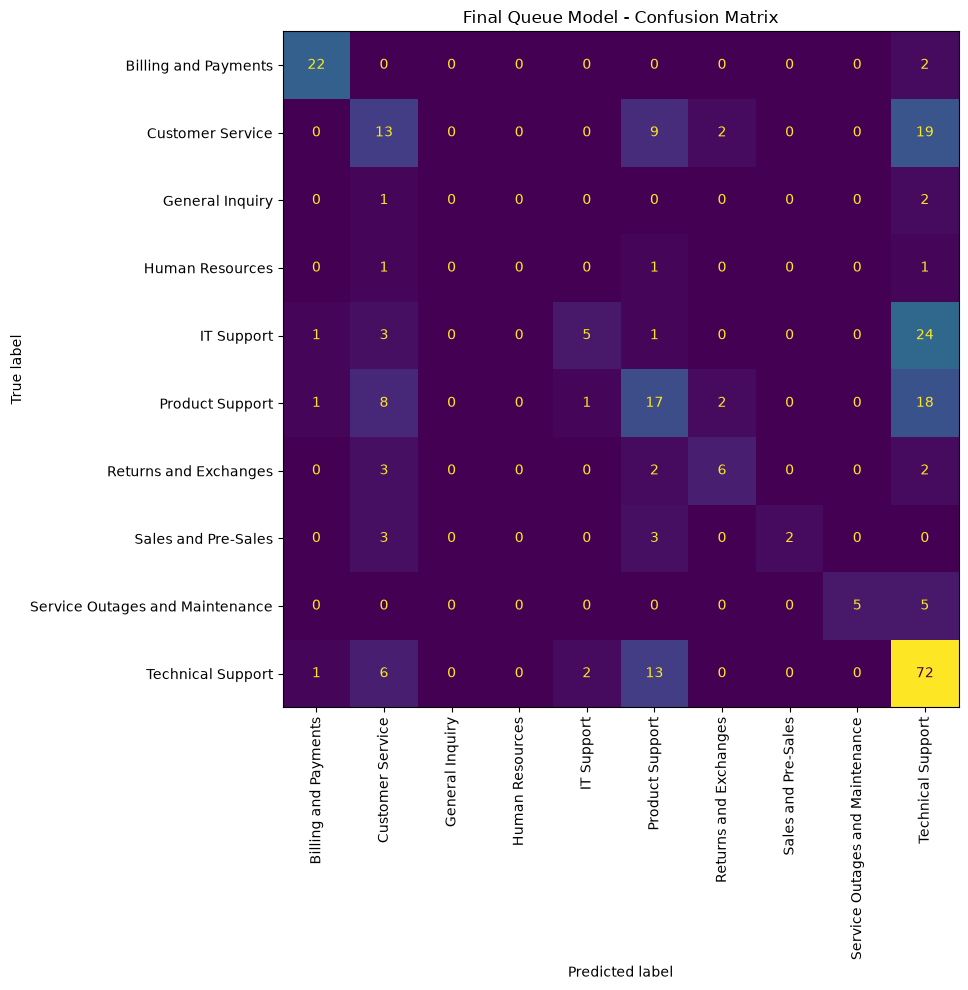

In [67]:

# ## Step 13: Final Queue Model Evaluation

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)
import matplotlib.pyplot as plt

# Predict the support queue for the test data
y_queue_pred_final = calibrated_svm.predict(X_test_tfidf_2)

# Calculate evaluation scores using the correct test labels
queue_accuracy = accuracy_score(y_queue_test, y_queue_pred_final)
queue_macro_f1 = f1_score(
    y_queue_test, y_queue_pred_final,
    average="macro", zero_division=0
)
queue_weighted_f1 = f1_score(
    y_queue_test, y_queue_pred_final,
    average="weighted", zero_division=0
)

# Display the overall evaluation results
print("FINAL QUEUE MODEL EVALUATION")
print("----------------------------")
print(f"Accuracy:       {queue_accuracy:.2%}")
print(f"Macro F1-score: {queue_macro_f1:.3f}")
print(f"Weighted F1:    {queue_weighted_f1:.3f}")

# Display precision, recall, and F1-score for every queue
print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_queue_test,
    y_queue_pred_final,
    zero_division=0
))

# Plot the confusion matrix
queue_labels = calibrated_svm.classes_
queue_cm = confusion_matrix(
    y_queue_test,
    y_queue_pred_final,
    labels=queue_labels
)

queue_display = ConfusionMatrixDisplay(
    confusion_matrix=queue_cm,
    display_labels=queue_labels
)

fig, ax = plt.subplots(figsize=(12, 10))
queue_display.plot(
    ax=ax,
    xticks_rotation=90,
    values_format="d",
    colorbar=False
)
plt.title("Final Queue Model - Confusion Matrix")
plt.tight_layout()
plt.show()


In [70]:

# ## Step 14: Find priority test features

# Take a snapshot of the current variable names
variable_names = list(globals().keys())

# Display variables that may contain priority test features
for name in variable_names:
    if "priority" in name.lower() or (
        name.startswith("X_") and "test" in name.lower()
    ):
        value = globals()[name]

        # Print the name, type, and shape when available
        print(
            name,
            type(value).__name__,
            getattr(value, "shape", "")
        )


y_priority Series (1391,)
X_test Series (279,)
y_priority_train Series (1112,)
y_priority_test Series (279,)
X_test_tfidf csr_matrix (279, 5000)
priority_model LogisticRegression 
y_priority_pred ndarray (279,)
priority_accuracy float 
priority_cm ndarray (3, 3)
X_test_tfidf_2 csr_matrix (279, 10000)
loaded_priority_model LogisticRegression 
loaded_priority_vectorizer TfidfVectorizer 
priority_features csr_matrix (1, 5000)
predicted_priority str 


FINAL PRIORITY MODEL EVALUATION
--------------------------------
Accuracy:       59.50%
Macro F1-score: 0.564
Weighted F1:    0.600

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        high       0.71      0.64      0.67       118
         low       0.39      0.47      0.42        47
      medium       0.59      0.61      0.60       114

    accuracy                           0.59       279
   macro avg       0.56      0.57      0.56       279
weighted avg       0.61      0.59      0.60       279



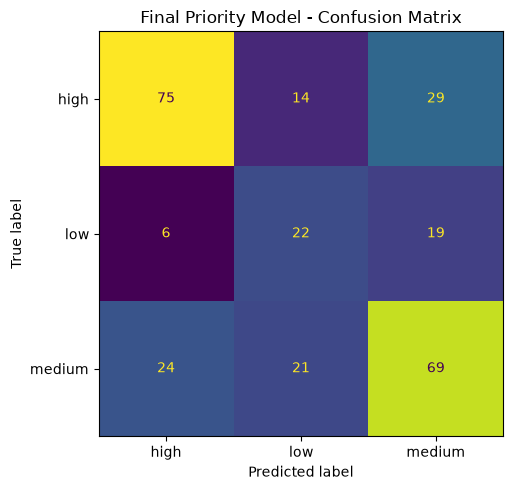

In [71]:

# ## Step 15: Final Priority Model Evaluation

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)
import matplotlib.pyplot as plt

# Predict ticket priorities using the test features
y_priority_pred_final = priority_model.predict(X_test_tfidf)

# Calculate evaluation metrics using the correct test labels
priority_accuracy = accuracy_score(
    y_priority_test,
    y_priority_pred_final
)

priority_macro_f1 = f1_score(
    y_priority_test,
    y_priority_pred_final,
    average="macro",
    zero_division=0
)

priority_weighted_f1 = f1_score(
    y_priority_test,
    y_priority_pred_final,
    average="weighted",
    zero_division=0
)

# Display overall evaluation results
print("FINAL PRIORITY MODEL EVALUATION")
print("--------------------------------")
print(f"Accuracy:       {priority_accuracy:.2%}")
print(f"Macro F1-score: {priority_macro_f1:.3f}")
print(f"Weighted F1:    {priority_weighted_f1:.3f}")

# Display precision, recall, and F1-score for each priority
print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_priority_test,
    y_priority_pred_final,
    zero_division=0
))

# Generate the confusion matrix
priority_labels = priority_model.classes_

priority_cm = confusion_matrix(
    y_priority_test,
    y_priority_pred_final,
    labels=priority_labels
)

# Plot the confusion matrix
priority_display = ConfusionMatrixDisplay(
    confusion_matrix=priority_cm,
    display_labels=priority_labels
)

fig, ax = plt.subplots(figsize=(7, 5))

priority_display.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

plt.title("Final Priority Model - Confusion Matrix")
plt.tight_layout()
plt.show()
